In [1]:
%load_ext autoreload
%autoreload 2

### Setup (Colab or local)

In [2]:
%load_ext autoreload
%autoreload 2

import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/Varun-Ponugoti/DLAI.git"
PROJECT  = "generative"                     # this project's folder inside DLAI
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    clone_dir = Path("/content/DLAI")
    if clone_dir.exists():
        subprocess.run(["git", "-C", str(clone_dir), "pull", "--ff-only"], check=False)
    else:
        subprocess.run(["git", "clone", REPO_URL, str(clone_dir)], check=True)
    repo = clone_dir / PROJECT
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(repo / "requirements.txt")], check=True)
    os.chdir(repo)
else:
    # Walk up from wherever Jupyter was launched until we find the project folder
    repo = Path.cwd().resolve()
    while not (repo / "src").is_dir() and repo != repo.parent:
        repo = repo.parent
    if not (repo / "src").is_dir():
        raise RuntimeError("Couldn't find the project folder (a folder containing src/).")

if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
print("Project root:", repo, "| Colab:", IN_COLAB)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Project root: /home/varun/Documents/Courses/Deep learning/DLAI/generative | Colab: False


### Environment & config

In [3]:
import json, time
import numpy as np
import torch
from PIL import Image
from IPython.display import display

from src.utils import REPO_ROOT, milestone_dir, get_device, environment_info

DEVICE, DTYPE = get_device()
ENV = environment_info(DEVICE, DTYPE)
ENV

{'device': 'cuda',
 'gpu': 'NVIDIA GeForce RTX 3060 Laptop GPU',
 'dtype': 'torch.float16',
 'versions': {'python': '3.10.21',
  'torch': '2.14.0+cu130',
  'diffusers': '0.41.0',
  'transformers': '5.18.0'}}

In [4]:
OUT_DIR = milestone_dir("milestone2_conditioning")

MODEL_ID   = "stable-diffusion-v1-5/stable-diffusion-v1-5"  # fallback: "sd-legacy/stable-diffusion-v1-5"
SEED       = 42
IMAGE_SIZE = 512
NEG_PROMPT = "blurry, lowres, distorted, watermark, text"

print("Outputs:", OUT_DIR)

Outputs: /home/varun/Documents/Courses/Deep learning/DLAI/generative/outputs/milestone2_conditioning


### Text encoder integration

In [5]:
from src.pipeline import load_text_encoder, load_diffusion_components, encode_prompt, generate
from src.utils import make_generator

tokenizer, text_encoder = load_text_encoder(MODEL_ID, DEVICE, DTYPE)
unet, vae, scheduler = load_diffusion_components(MODEL_ID, DEVICE, DTYPE)

def n_params(model):
    return f"{sum(p.numel() for p in model.parameters())/1e6:.0f}M"

print(f"Text encoder: {type(text_encoder).__name__:<22} {n_params(text_encoder)} params")
print(f"UNet        : {type(unet).__name__:<22} {n_params(unet)} params")
print(f"VAE         : {type(vae).__name__:<22} {n_params(vae)} params")
print(f"Scheduler   : {type(scheduler).__name__}")

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

/home/varun/Anaconda/ENTER/envs/deeplearning/lib/python3.10/site-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Text encoder: CLIPTextModel          123M params
UNet        : UNet2DConditionModel   860M params
VAE         : AutoencoderKL          84M params
Scheduler   : PNDMScheduler


In [6]:
# The two dimensions that must match for text conditioning to work
text_dim = text_encoder.config.hidden_size
attn_dim = unet.config.cross_attention_dim
print(f"Text encoder hidden size : {text_dim}")
print(f"UNet cross-attention dim : {attn_dim}  -> {'match' if text_dim == attn_dim else 'MISMATCH'}")

# One UNet call, exactly as generate() does it
prompt = "a red apple on a wooden table"
text_emb = torch.cat([encode_prompt(NEG_PROMPT, tokenizer, text_encoder),
                      encode_prompt(prompt, tokenizer, text_encoder)])

latent_size = IMAGE_SIZE // 8
latents = torch.randn(2, unet.config.in_channels, latent_size, latent_size,
                      device=DEVICE, dtype=DTYPE)
t = torch.tensor(999, device=DEVICE)

with torch.no_grad():
    noise_pred = unet(latents, t, encoder_hidden_states=text_emb).sample

print(f"\nText embeddings  : {tuple(text_emb.shape)}   [uncond, cond] x 77 tokens x {text_dim}")
print(f"Latents in       : {tuple(latents.shape)}")
print(f"Noise prediction : {tuple(noise_pred.shape)}   same shape as the latents")

Text encoder hidden size : 768
UNet cross-attention dim : 768  -> match

Text embeddings  : (2, 77, 768)   [uncond, cond] x 77 tokens x 768
Latents in       : (2, 4, 64, 64)
Noise prediction : (2, 4, 64, 64)   same shape as the latents


### Verify the integration

Generated in 4.4s
Mean pixel difference vs. M1: 0.31 | max: 13  (0–255 scale)


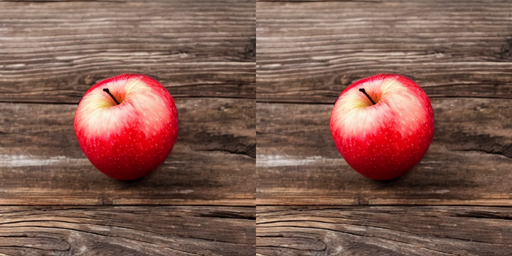

In [7]:
BASE_GUIDANCE = 7.5
BASE_STEPS    = 30

start = time.time()
ours = generate(
    "a red apple on a wooden table",
    tokenizer, text_encoder, unet, vae, scheduler,
    negative_prompt=NEG_PROMPT,
    guidance_scale=BASE_GUIDANCE,
    num_steps=BASE_STEPS,
    height=IMAGE_SIZE, width=IMAGE_SIZE,
    generator=make_generator(SEED, DEVICE),
)
print(f"Generated in {time.time() - start:.1f}s")

m1 = Image.open(REPO_ROOT / "outputs/milestone1_baseline/images/p1_simple_object.png").convert("RGB")
diff = np.abs(np.asarray(ours, dtype=np.float32) - np.asarray(m1, dtype=np.float32))
print(f"Mean pixel difference vs. M1: {diff.mean():.2f} | max: {diff.max():.0f}  (0–255 scale)")

side_by_side = Image.new("RGB", (IMAGE_SIZE * 2, IMAGE_SIZE))
side_by_side.paste(ours, (0, 0))
side_by_side.paste(m1, (IMAGE_SIZE, 0))
display(side_by_side.resize((IMAGE_SIZE, IMAGE_SIZE // 2)))   # left: ours | right: M1 pipeline

### Baseline conditional generation

In [8]:
from src.utils import make_grid, add_caption, save_run_log, write_gallery

PROMPTS = [
    ("p1_simple_object", "a red apple on a wooden table"),
    ("p2_multi_object",  "a cat and a dog sitting together on a park bench"),
    ("p3_spatial",       "a blue cube to the left of a yellow sphere on a white floor"),
    ("p4_stylistic",     "a mountain lake at sunrise, in the style of a watercolor painting"),
    ("p5_abstract",      "the feeling of nostalgia, surreal dreamlike digital art"),
]

RUNS = {}


def run_and_record(experiment, tag, prompt, *, guidance_scale=BASE_GUIDANCE,
                   num_steps=BASE_STEPS, sched=None, extra=None):
    sched = sched or scheduler
    start = time.time()
    img = generate(
        prompt, tokenizer, text_encoder, unet, vae, sched,
        negative_prompt=NEG_PROMPT,
        guidance_scale=guidance_scale,
        num_steps=num_steps,
        height=IMAGE_SIZE, width=IMAGE_SIZE,
        generator=make_generator(SEED, DEVICE),   # same seed for every image
    )
    seconds = round(time.time() - start, 2)

    (OUT_DIR / experiment).mkdir(exist_ok=True)
    rel_path = f"{experiment}/{tag}.png"
    img.save(OUT_DIR / rel_path)

    RUNS[rel_path] = {
        "experiment": experiment,
        "tag": tag,
        "prompt": prompt,
        "negative_prompt": NEG_PROMPT,
        "seed": SEED,
        "steps": num_steps,
        "guidance_scale": guidance_scale,
        "scheduler": type(sched).__name__,
        "height": IMAGE_SIZE,
        "width": IMAGE_SIZE,
        "seconds": seconds,
        "image": rel_path,
        **(extra or {}),
    }
    return img


def save_records():
    save_run_log(OUT_DIR, ENV, RUNS, model_id=MODEL_ID)
    write_gallery(OUT_DIR, RUNS, "Milestone 2 — Conditional generation")

In [9]:
baseline_images = []
for tag, prompt in PROMPTS:
    img = run_and_record("baseline", tag, prompt)
    baseline_images.append(img)
    print(f"[{RUNS[f'baseline/{tag}.png']['seconds']:>5.1f}s] {tag}")

baseline_grid = make_grid([add_caption(img, tag) for img, (tag, _) in zip(baseline_images, PROMPTS)],
                          cols=len(PROMPTS))
baseline_grid.save(OUT_DIR / "baseline" / "grid.png")
save_records()
print("Saved to", OUT_DIR / "baseline")

[  4.4s] p1_simple_object
[  4.4s] p2_multi_object
[  4.4s] p3_spatial
[  4.4s] p4_stylistic
[  4.5s] p5_abstract
Saved to /home/varun/Documents/Courses/Deep learning/DLAI/generative/outputs/milestone2_conditioning/baseline


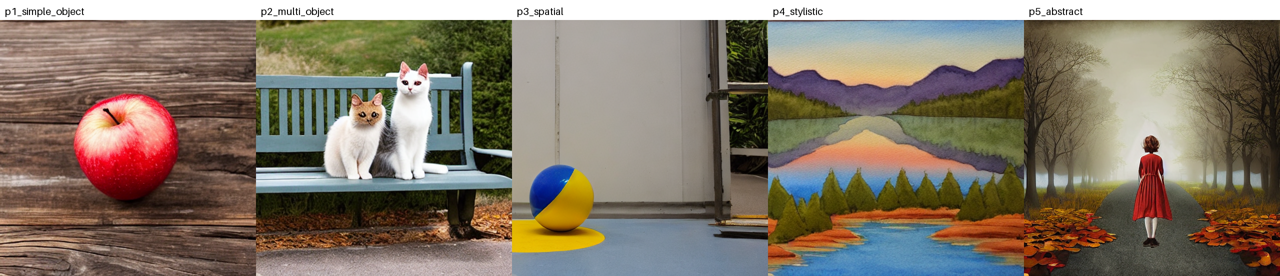

In [10]:
display(baseline_grid.resize((baseline_grid.width // 2, baseline_grid.height // 2)))